In [16]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [2]:
# DISPLAY DATA

def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)
        

Text(0.5, 1.0, 'M13 G-band blob model')

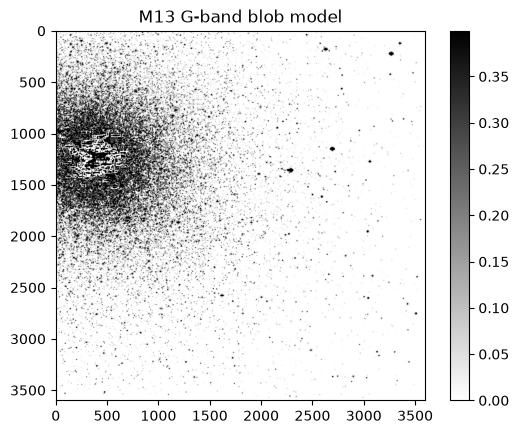

In [8]:
#make the figure
plt.figure()

#read in the data and header
data,headerM13g_blob = fits.getdata('/home/m724p633/ASTR596/Data/M13 G-band blobmodel.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 G-band blob model")

In [4]:
M13g_blob = WCS(headerM13g_blob)
print(M13g_blob)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 250.293103448276 36.5
CRPIX : 1800.5 1800.5
CD1_1 CD1_2  : -7.27777777777778e-05 0.0
CD2_1 CD2_2  : 0.0 7.27777777777778e-05
NAXIS : 3600  3600


Text(0.5, 1.0, 'M13 R-band blob model')

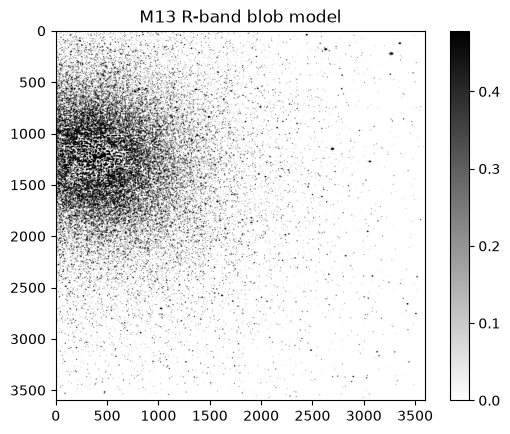

In [9]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('/home/m724p633/ASTR596/Data/M13 R-band blobmodel.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 R-band blob model")

Text(0.5, 1.0, 'M13 G-band image')

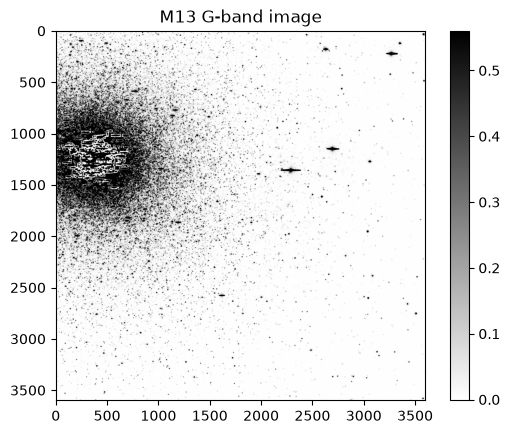

In [10]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('/home/m724p633/ASTR596/Data/M13 G-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 G-band image")

Text(0.5, 1.0, 'M13 R-band image')

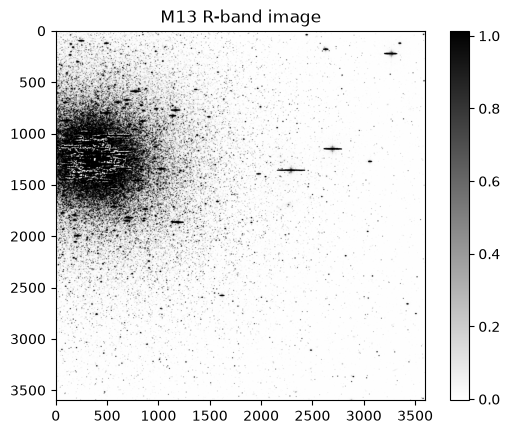

In [7]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('/home/m724p633/ASTR596/Data/legacysurvey-2502p365-image-r.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M13 R-band image")

**Combine the images in each filter.**

In [11]:
# make a list of all images
image_list_M13 = glob.glob('M13*.fits')
print(image_list_M13)

['M13 G-band blobmodel.fits', 'M13 R-band image.fits', 'M13 R-band blobmodel.fits', 'M13 G-band image.fits']


In [13]:
# create lists for images in each filter
rimage_list_M13 = glob.glob('M13 R*.fits')
gimage_list_M13 = glob.glob('M13 G*.fits')

#read in the first r-band image in that list using fits.getdata.  This image will be used as a target whose WCS
# will be used for all other images to be transformed onto
rimage_M13, rheader_M13 = fits.getdata(rimage_list_M13[0],header=True)
target_wcs_M13 = WCS(header)

print(target_wcs_M13)
#**********************
#now print out each of the image lists to see if they make sense
print(rimage_list_M13)
print(gimage_list_M13)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 250.293103448276 36.5
CRPIX : 1800.5 1800.5
CD1_1 CD1_2  : -7.27777777777778e-05 0.0
CD2_1 CD2_2  : 0.0 7.27777777777778e-05
NAXIS : 3600  3600
['M13 R-band image.fits', 'M13 R-band blobmodel.fits']
['M13 G-band blobmodel.fits', 'M13 G-band image.fits']


**Combine the images.**

Text(0.5, 1.0, 'M13 R-band image')

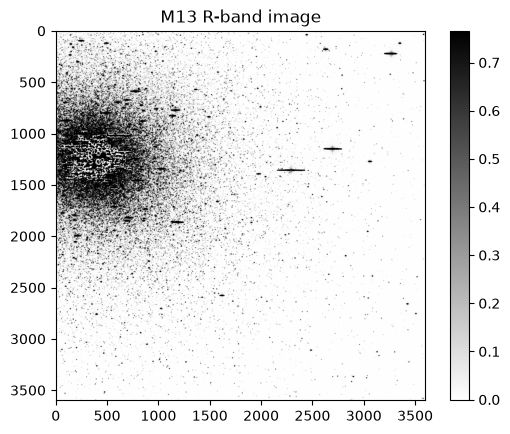

In [24]:
# reproject all the images to align them with the first image in each of the lists for a given filter.
# R-band data
reprojected = []
#loop through each image name
for image_name in rimage_list_M13:
    #read the image into a "CCDData" object
    img = CCDData.read(image_name, hdu=1)
    #take each image, and reproject it onto an identical coordinate grid to the target image
    new_image = wcs_project(img, target_wcs_M13)
    #this is a list of all the reprojected images
    reprojected.append(new_image)

# combine the reprojected images into one image
combiner = Combiner(reprojected)
stacked_image = combiner.average_combine()


# save the combined image
fits.writeto('M13R.fits',stacked_image,overwrite=True,header=rheader_M13)
# display the combined image
plt.figure()
imdisplay(stacked_image)
plt.title('M13 R-band image')

Text(0.5, 1.0, 'M13 G-band image')

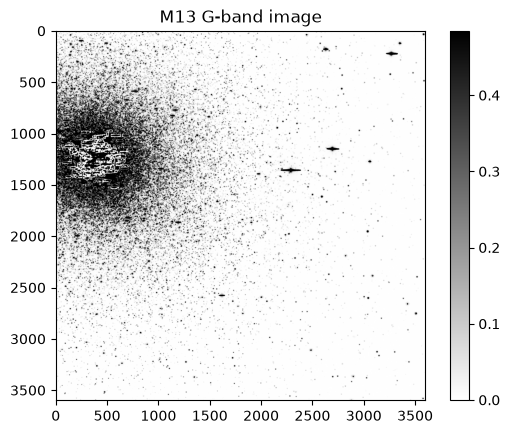

In [26]:
# G-band data
reprojected = []
#loop through each image name
for image_name in gimage_list_M13:
    #read the image into a "CCDData" object
    img = CCDData.read(image_name, hdu=1)
    #take each image, and reproject it onto an identical coordinate grid to the target image
    new_image = wcs_project(img, target_wcs_M13)
    #this is a list of all the reprojected images
    reprojected.append(new_image)

# combine the reprojected images into one image
combiner = Combiner(reprojected)
stacked_image = combiner.average_combine()


# save the combined image
fits.writeto('M13G.fits',stacked_image,overwrite=True,header=rheader_M13)
# display the combined image
plt.figure()
imdisplay(stacked_image)
plt.title('M13 G-band image')

**Measure FWHM**

In [33]:
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess, pixels
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [38]:
M13_fwhmlistG = calc_fwhm('M13G.fits', [(1850.53,884.623), (2593.54,1615.25), (2333.49,2215.85), (1268.51,3225.1), (1726.7,3181.76)])
print('FHWM of G-band image in pix: ', np.mean(M13_fwhmlistG))
M13_fwhmlistR = calc_fwhm('M13R.fits',[(1279.86,2698.8), (2332.46,2213.78), (2719.44,1501.73), (3018.71,1455.29), (2399.53,2998.07)])
print('FHWM of R-band image in pix: ',np.mean(M13_fwhmlistR))

The FWHM of the stars in M13G.fits in pixels are [4.92111941 9.75868962 6.0136674  5.0778336  5.05658792]
FHWM of G-band image in pix:  6.165579591646752
The FWHM of the stars in M13R.fits in pixels are [4.5084621  4.46931332 4.31349007 4.29404369 4.48520904]
FHWM of R-band image in pix:  4.414103644749862


**Measure Phtometry of Stars**

In [43]:
#read in the G-band image
M13data_G, M13header_G = fits.getdata('M13G.fits',header=True)

In [44]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M13mean_G, M13median_G, M13std_G = sigma_clipped_stats(M13data_G, sigma=3.0)

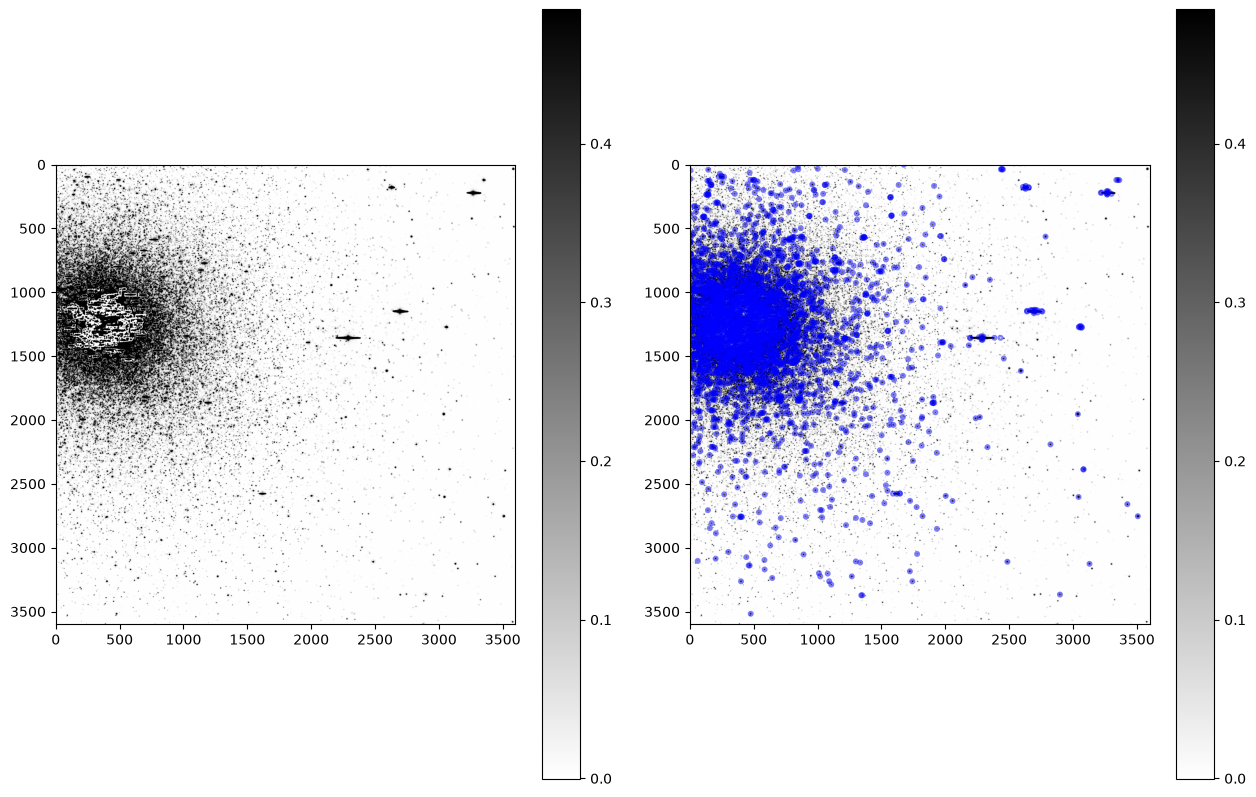

In [65]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=6.17, threshold=80.*M13std_G)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M13sources_G = daofind(M13data_G - M13median_G)

# convert pixel locations of images to ra and dec using the image header
wcs_G = WCS(M13header_G)
M13ra_G,M13dec_G = wcs_G.wcs_pix2world(M13sources_G['xcentroid'],M13sources_G['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots G-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M13data_G)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M13sources_G['xcentroid'], M13sources_G['ycentroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M13data_G)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

Text(0.5, 1.0, 'M13 G-band')

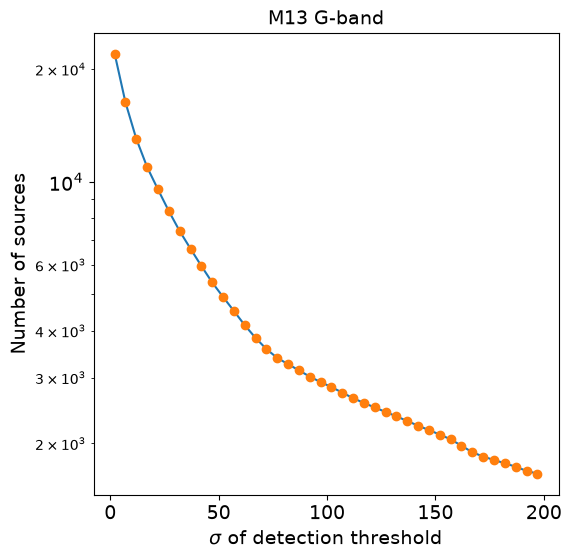

In [67]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_G = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=6.17, threshold=thresh*M13std_G)
    M13sources_Gtmp = daofind(M13data_G - M13median_G)
    nsources_G[ithresh] = len(M13sources_Gtmp)

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_G)
ax.plot(thresharr,nsources_G, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M13 G-band', fontsize=14)

**Repeat for R-band**

In [52]:
#read in the R-band image
M13data_R, M13header_R = fits.getdata('M13R.fits',header=True)

In [53]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M13mean_R, M13median_R, M13std_R = sigma_clipped_stats(M13data_R, sigma=3.0)

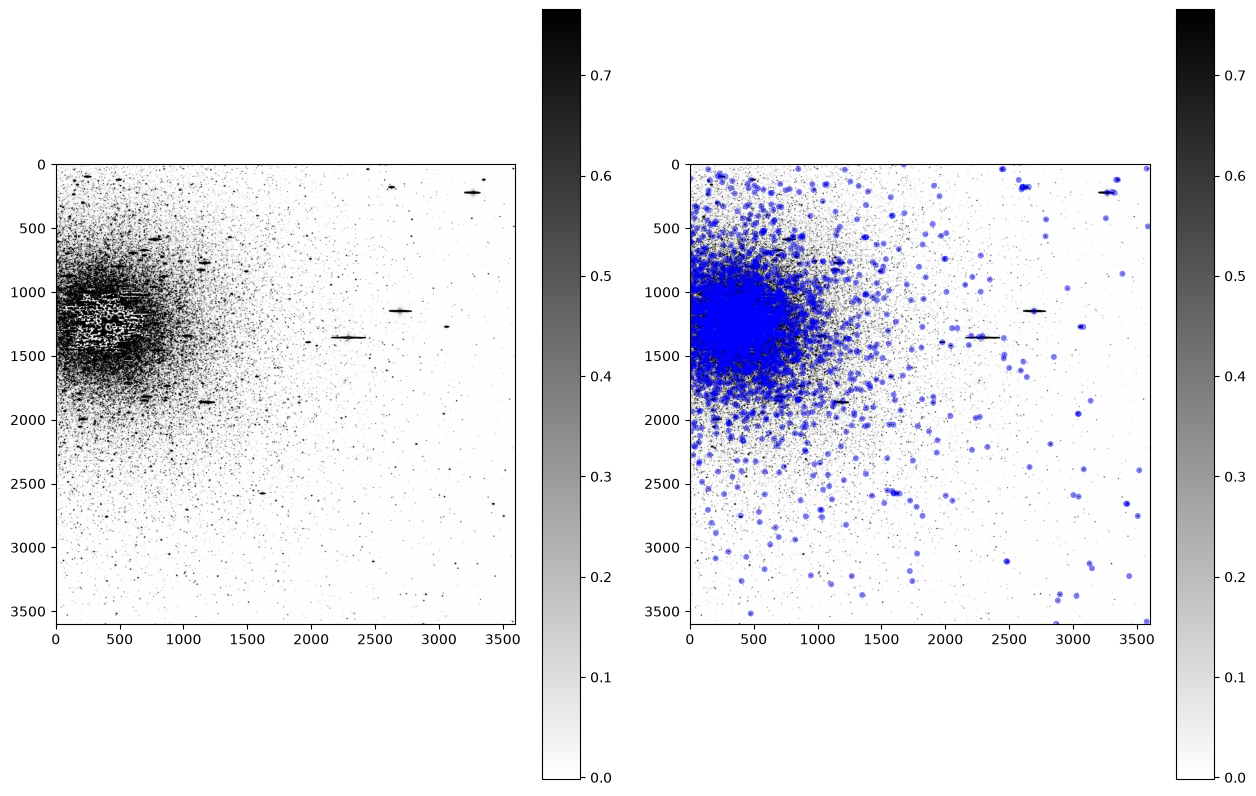

In [62]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=4.41, threshold=40.*M13std_R)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M13sources_R = daofind(M13data_R - M13median_R)

# convert pixel locations of images to ra and dec using the image header
wcs_R = WCS(M13header_R)
M13ra_R,M13dec_R = wcs_R.wcs_pix2world(M13sources_R['xcentroid'],M13sources_R['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots R-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M13data_R)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M13sources_R['xcentroid'], M13sources_R['ycentroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M13data_R)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

Text(0.5, 1.0, 'M13 R-band')

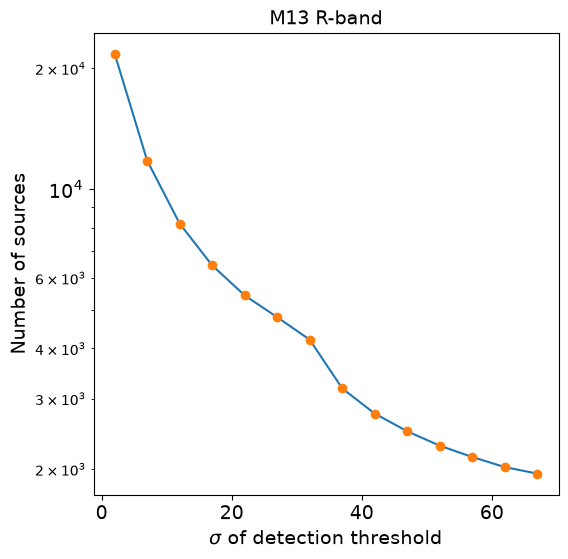

In [61]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,70.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_R = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=4.41, threshold=thresh*M13std_R)
    M13sources_Rtmp = daofind(M13data_R - M13median_R)
    nsources_R[ithresh] = len(M13sources_Rtmp)

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_R)
ax.plot(thresharr,nsources_R, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M13 R-band', fontsize=14)

**Comparing positions of R and G-band sources**

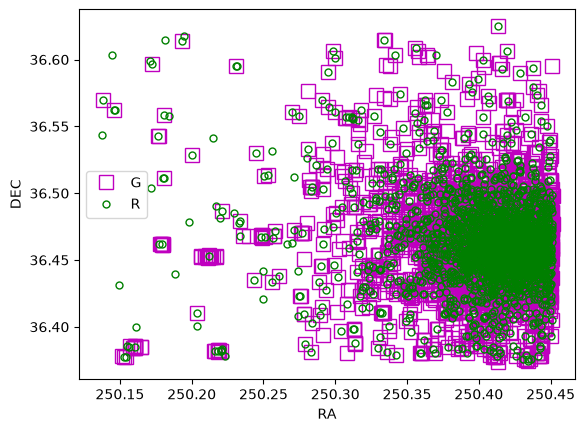

In [68]:
# make a plot of the RA and DEC of the sources in the B and V images

#select sources away from image boundary in B-band image
#boolean flags for good positions in the B and V-band images
xb = M13sources_G['xcentroid']
yb = M13sources_G['ycentroid']
xv = M13sources_R['xcentroid']
yv = M13sources_R['ycentroid']

noedgeflag_G = (xb > 50) & (xb < fits.getdata('M13G.fits').shape[1] - 50) &  (yb > 50) & (yb < fits.getdata('M13G.fits').shape[1] - 50)
noedgeflag_R = (xv > 50) & (xv < fits.getdata('M13R.fits').shape[1] - 50) &  (yv > 50) & (yv < fits.getdata('M13R.fits').shape[1] - 50)


# open a figure
plt.figure()

# plot the positions of the B sources
plt.plot(M13ra_G[noedgeflag_G],M13dec_G[noedgeflag_G],'ms',mfc='None',markersize=10,label='G')

# plot the positions of the V sources
plt.plot(M13ra_R[noedgeflag_R],M13dec_R[noedgeflag_R],'g.',mfc='None',markersize=10,label='R')

# add a legend
plt.legend()
# label your x axis
plt.xlabel('RA')
# label your y axis
plt.ylabel('DEC')
# save your plot
plt.savefig('M13_RAvsDec_photometry_plot.png')

**Match the catalogs of G and R photometry using their RA and DEC**

In [69]:
from astropy.coordinates import SkyCoord
from astropy import units as u

In [70]:
#this creates a SkyCoord object containing the G and R catalogs
M13G_catalog = SkyCoord(ra=M13ra_G*u.degree, dec=M13dec_G*u.degree)
M13R_catalog = SkyCoord(ra=M13ra_R*u.degree, dec=M13dec_R*u.degree)

#this matches the two catalogs and outputs an array of indices, idx that when passed to v_catalog
#gives the ids of the match sources in the b_catalog.
idx, d2d, d3d = M13G_catalog.match_to_catalog_sky(M13R_catalog)

# we are going to keep matches that have offsets less than 2 arcseconds
# NOTE: this might not be small enough if you were
# matching stars in a globular cluster
matchflag = d2d < 2./3600*u.deg
bmag = M13sources_G['mag'][matchflag]
vmag = M13sources_R['mag'][idx[matchflag]]

**Adjust the magnitudes**

* Daofind assumes zero point=0. It calculates magnitude as: mag=-2.5log(flux)
* Calibrated magnitude: mag=-2.5log(flux) + ZP

In [77]:
# Converting instrumental magnitudes to calibrated magnitudes
#print(list(M13header_G.keys()))
M13calibrated_Gmag = bmag + float(M13header_G['MAGZERO'])
M13calibrated_Rmag = vmag + float(M13header_R['MAGZERO'])

print(float(M13header_G['MAGZERO']))
print(float(M13header_R['MAGZERO']))

22.5
22.5


**Plot Color-Magnitude Diagram**

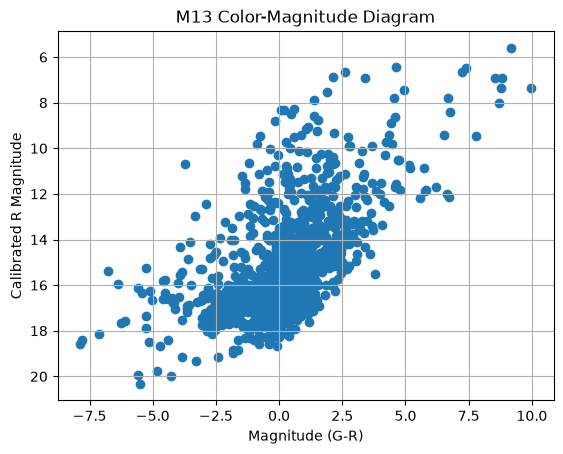

In [78]:
plt.scatter(M13calibrated_Gmag-M13calibrated_Rmag, M13calibrated_Rmag)
plt.gca().invert_yaxis()

# x-axis
plt.xlabel('Magnitude (G-R)')
# y-axis
plt.ylabel('Calibrated R Magnitude')
# title
plt.title('M13 Color-Magnitude Diagram')
plt.grid(True)